# 03 · Pipeline de variables y estabilidad (PSI)

**Objetivo:** preparar las variables para cada familia de modelos y comprobar que son **estables** entre entrenamiento (2012–2014) y fuera de tiempo (2015).

Regla de oro: todo lo que el pipeline aprende (percentiles, medianas, WoE) se ajusta **solo con entrenamiento**. El código está en `src/credit_lab/transformadores.py`.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from credit_lab.poblacion import cargar_poblacion
from credit_lab.features import derivar, ARBOLES
from credit_lab.transformadores import preprocesador, columnas, Limpieza
from credit_lab.metricas import psi

pd.set_option("display.float_format", "{:,.3f}".format)
AZUL, NARANJA, AMARILLO = "#2a78d6", "#eb6834", "#eda100"
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e5e4df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.titlecolor": TINTA, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

df = derivar(cargar_poblacion())
tr, oot = df[df["muestra"].eq("train")], df[df["muestra"].eq("oot")]

# Población ANTES de la decisión 003 (desde ene-2012), solo para el diagnóstico
df0 = derivar(cargar_poblacion(inicio=pd.Timestamp("2012-01-01")))
tr0, oot0 = df0[df0["muestra"].eq("train")], df0[df0["muestra"].eq("oot")]

## 1. Los tres pipelines

| Familia | Pasos | Nulos |
|---|---|---|
| Logística | limpieza → winsorización p1–p99 → **WoE** | Tramo propio con su WoE |
| Árboles | limpieza → winsorización → categóricas a códigos | Se dejan: XGBoost, LightGBM y RF los manejan |
| Red neuronal | limpieza → winsorización → imputación con mediana + indicador de nulo → estandarización; one-hot para categóricas | Imputados |

**Limpieza (reglas fijas):** `9.999.999` → nulo; `home_ownership` NONE/ANY → OTHER; `revol_util` con tope de 150%.

In [2]:
resumen = []
for familia in ["logistica", "arboles", "red"]:
    p = preprocesador(familia)
    Xt = p.fit_transform(tr[columnas(familia)], tr["malo"])
    Xo = p.transform(oot[columnas(familia)])
    resumen.append({"familia": familia, "variables_entrada": len(columnas(familia)),
                    "columnas_salida": Xt.shape[1], "nulos_train": int(Xt.isna().sum().sum()),
                    "nulos_oot": int(Xo.isna().sum().sum())})
pd.DataFrame(resumen)

,familia,variables_entrada,columnas_salida,nulos_train,nulos_oot
0,logistica,16,16,0,0
1,arboles,31,31,153092,142081
2,red,31,114,0,0


## 2. Diagnóstico: PSI con la población original (desde ene-2012)

Guía: < 0,1 estable · 0,1–0,25 cambio moderado · > 0,25 cambio fuerte.

In [3]:
def tabla_psi(base, tr, oot):
    limpio = Limpieza().transform(base[ARBOLES])
    a, b = limpio.loc[tr.index], limpio.loc[oot.index]
    return pd.DataFrame({
        "psi": {c: psi(a[c], b[c]) for c in ARBOLES},
        "psi_sin_nulos": {c: psi(a[c].dropna(), b[c].dropna()) for c in ARBOLES},
        "nulos_train_%": a.isna().mean() * 100,
        "nulos_oot_%": b.isna().mean() * 100,
    }).sort_values("psi", ascending=False)

estab = tabla_psi(df0, tr0, oot0)
estab.head(12)

,psi,psi_sin_nulos,nulos_train_%,nulos_oot_%
pct_tl_nvr_dlq,0.844,0.010,7.395,0.000
mo_sin_old_rev_tl_op,0.840,0.011,7.358,0.000
num_actv_rev_tl,0.839,0.009,7.358,0.000
tot_cur_bal,0.836,0.006,7.358,0.000
avg_cur_bal,0.835,0.005,7.361,0.000
num_tl_90g_dpd_24m,0.830,0.000,7.358,0.000
total_rev_hi_lim,0.729,0.010,7.359,0.000
mort_acc,0.201,0.007,1.966,0.000
total_bc_limit,0.201,0.006,1.966,0.000
percent_bc_gt_75,0.047,0.029,2.972,1.090


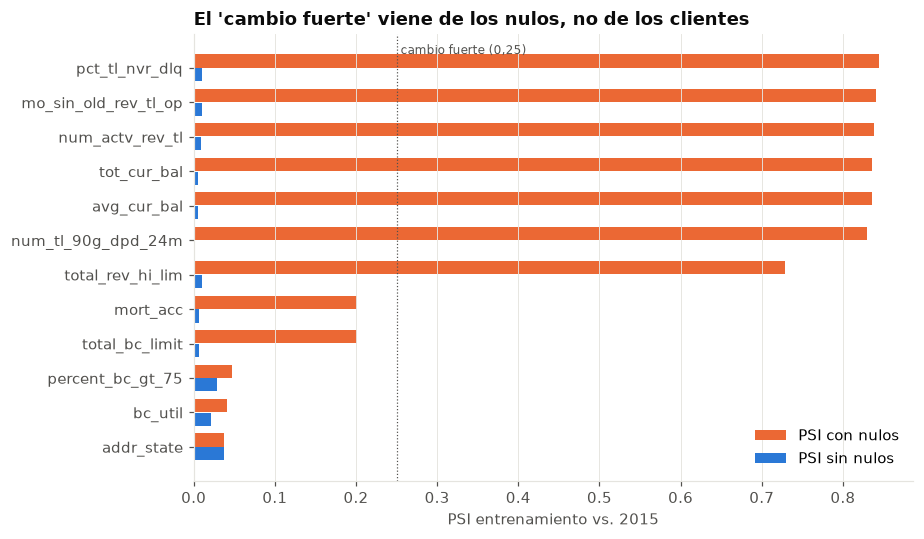

In [4]:
top = estab.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5))
y = np.arange(len(top))
ax.barh(y + 0.2, top["psi"], height=0.38, color=NARANJA, label="PSI con nulos")
ax.barh(y - 0.2, top["psi_sin_nulos"], height=0.38, color=AZUL, label="PSI sin nulos")
ax.set_yticks(y, top.index)
ax.axvline(0.25, color=TINTA_2, linestyle=":", linewidth=0.8)
ax.text(0.255, len(top) - 0.6, "cambio fuerte (0,25)", fontsize=8, color=TINTA_2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("PSI entrenamiento vs. 2015")
ax.set_title("El 'cambio fuerte' viene de los nulos, no de los clientes")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()

## 3. ¿De dónde salen esos nulos?

In [5]:
vars_nulas = ["tot_cur_bal", "mort_acc", "total_bc_limit", "pct_tl_nvr_dlq"]
mes = df0["issue_d"].dt.to_period("M")
nulos_mes = df0.groupby(mes)[vars_nulas].apply(lambda x: x.isna().mean() * 100)
nulos_mes[(nulos_mes > 0).any(axis=1)]

,tot_cur_bal,mort_acc,total_bc_limit,pct_tl_nvr_dlq
issue_d,,,,
2012-01,100.000,100.000,100.000,100.000
2012-02,100.000,100.000,100.000,100.000
2012-03,100.000,78.065,78.065,100.000
2012-04,100.000,1.642,1.642,100.000
2012-05,100.000,0.000,0.000,100.000
2012-06,100.000,0.000,0.000,100.000
2012-07,100.000,0.000,0.000,100.000
2012-08,83.883,0.000,0.000,83.883
2012-09,1.161,0.000,0.000,1.161


**Hallazgo:** Lending Club **empezó a reportar** estas variables de buró entre marzo y septiembre de 2012. Los nulos no son clientes sin información: son meses en que el campo no existía. En 2015 nunca hay nulos.

- Sin contar los nulos, el PSI es < 0,01: **los clientes no cambiaron**.
- El PSI de 0,84 es el tramo "NULO", que existe en entrenamiento (7%) y desaparece en 2015.
- Riesgo: un modelo podría aprender "nulo = 2012" y usar un patrón que nunca volverá a ver.

**→ Decisión 003 (Neider):** el entrenamiento arranca en **sep-2012** "para tener una población homogénea sin nulos artificiales".

In [6]:
excluidos = tr0[tr0["issue_d"] < "2012-09-01"]
pd.DataFrame({"prestamos": [len(excluidos), len(tr)],
              "tasa_malo": [excluidos["malo"].mean(), tr["malo"].mean()]},
             index=["excluidos (ene–ago 2012)", "entrenamiento final"])

,prestamos,tasa_malo
excluidos (ene–ago 2012),23209,0.141
entrenamiento final,283253,0.132


## 4. Después de la decisión 003: PSI con la población final

In [7]:
estab_final = tabla_psi(df, tr, oot)
print(f"PSI máximo: {estab_final['psi'].max():.3f} ({estab_final['psi'].idxmax()})")
estab_final.head(8)

PSI máximo: 0.036 (addr_state)


,psi,psi_sin_nulos,nulos_train_%,nulos_oot_%
addr_state,0.036,0.036,0.000,0.000
inq_last_6mths,0.032,0.032,0.000,0.000
percent_bc_gt_75,0.028,0.028,1.009,1.090
revol_util,0.024,0.024,0.052,0.045
dti,0.024,0.024,0.000,0.001
bc_util,0.021,0.021,1.038,1.070
purpose,0.017,0.017,0.000,0.000
emp_length,0.014,0.012,5.474,6.699


---
## ✍️ Conclusiones de Neider

1.
2.
3. 